# Свёрточные сети

До сих пор мы работали с глубокими полносвязными сетями и на их примере изучали разные методы оптимизации и архитектуры сетей. Полносвязные сети — удобный полигон для экспериментов, потому что они очень эффективны с вычислительной точки зрения, но на практике все передовые (state-of-the-art) результаты получены с помощью свёрточных сетей (CNN).

Сначала вы реализуете несколько типов слоёв, которые используются в свёрточных сетях, а затем с их помощью обучите свёрточную сеть на наборе данных CIFAR-10.

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment2'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'ConvolutionalNetworks.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment2\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: assignment2 (локальный путь скрыт)


> **Как редактировать файлы в Colab.** Часть кода нужно дописывать не в ноутбуках, а в файлах пакета `dlcv/` (например, `dlcv/layers.py`). Откройте панель «Файлы» (значок папки слева), найдите папку лабораторной в `drive/MyDrive/…` и дважды щёлкните по нужному файлу — он откроется в редакторе справа. Сохраните изменения (Ctrl+S). Благодаря `%autoreload` ноутбук подхватит новую версию кода без перезапуска среды выполнения.

In [2]:
# Подготовительная ячейка.
import numpy as np
import matplotlib.pyplot as plt
from dlcv.classifiers.cnn import *
from dlcv.data_utils import get_CIFAR10_data
from dlcv.gradient_check import eval_numerical_gradient_array, eval_numerical_gradient
from dlcv.layers import *
from dlcv.fast_layers import *
from dlcv.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ Возвращает относительную ошибку. """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Загружаем (предобработанные) данные CIFAR-10.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


# Свёртка: наивный прямой проход
Основа свёрточной сети — операция свёртки. В файле `dlcv/layers.py` реализуйте прямой проход свёрточного слоя в функции `conv_forward_naive`.

Об эффективности пока можно особенно не заботиться: пишите код так, как вам кажется понятнее всего.

Проверить реализацию можно, запустив следующую ячейку:

In [4]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([[[[-0.08759809, -0.10987781],
                           [-0.18387192, -0.2109216 ]],
                          [[ 0.21027089,  0.21661097],
                           [ 0.22847626,  0.23004637]],
                          [[ 0.50813986,  0.54309974],
                           [ 0.64082444,  0.67101435]]],
                         [[[-0.98053589, -1.03143541],
                           [-1.19128892, -1.24695841]],
                          [[ 0.69108355,  0.66880383],
                           [ 0.59480972,  0.56776003]],
                          [[ 2.36270298,  2.36904306],
                           [ 2.38090835,  2.38247847]]]])

# Сравниваем ваш выход с эталонным; разница должна быть порядка e-8
print('Проверка conv_forward_naive')
print('разница: ', rel_error(out, correct_out))

Проверка conv_forward_naive
разница:  2.212147649671884e-08


## Отступление: обработка изображений с помощью свёрток

Есть забавный способ одновременно проверить свою реализацию и лучше понять, какие операции умеют выполнять свёрточные слои. Подадим на вход два изображения и вручную зададим фильтры, выполняющие стандартные операции обработки изображений (перевод в оттенки серого и выделение границ). Прямой проход свёртки применит эти операции к каждому из входных изображений, а результаты мы визуализируем — это и будет быстрой проверкой (sanity check).

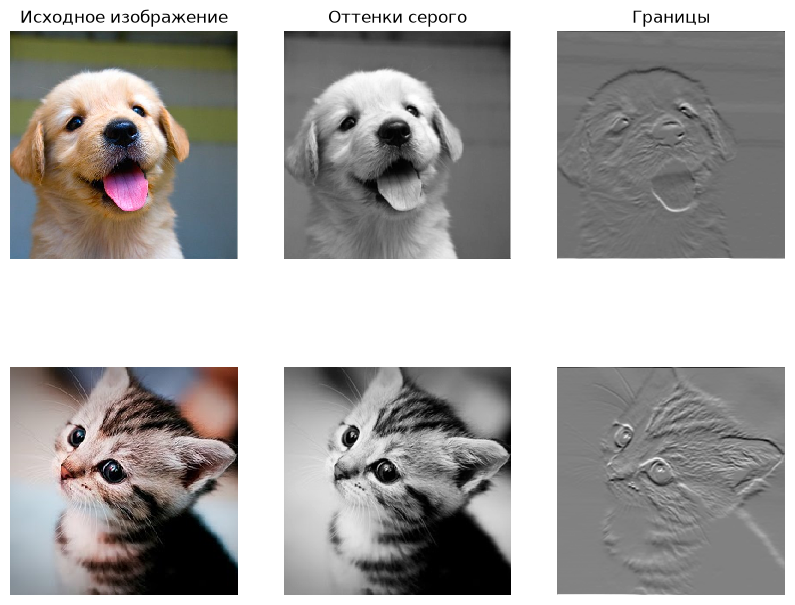

In [5]:
from PIL import Image

kitten = plt.imread('dlcv/notebook_images/kitten.jpg')
puppy = plt.imread('dlcv/notebook_images/puppy.jpg')
# изображение котёнка вытянуто в ширину, а изображение щенка уже квадратное
d = kitten.shape[1] - kitten.shape[0]
kitten_cropped = kitten[:, d//2:-d//2, :]

img_size = 200   # Уменьшите, если код работает слишком медленно
resized_puppy = np.array(Image.fromarray(puppy).resize((img_size, img_size)))
resized_kitten = np.array(Image.fromarray(kitten_cropped).resize((img_size, img_size)))
x = np.zeros((2, 3, img_size, img_size))
x[0, :, :, :] = resized_puppy.transpose((2, 0, 1))
x[1, :, :, :] = resized_kitten.transpose((2, 0, 1))

# Задаём веса свёрточного слоя: 2 фильтра размером 3x3
w = np.zeros((2, 3, 3, 3))

# Первый фильтр переводит изображение в оттенки серого.
# Задаём красный, зелёный и синий каналы фильтра.
w[0, 0, :, :] = [[0, 0, 0], [0, 0.3, 0], [0, 0, 0]]
w[0, 1, :, :] = [[0, 0, 0], [0, 0.6, 0], [0, 0, 0]]
w[0, 2, :, :] = [[0, 0, 0], [0, 0.1, 0], [0, 0, 0]]

# Второй фильтр выделяет горизонтальные границы в синем канале.
w[1, 2, :, :] = [[1, 2, 1], [0, 0, 0], [-1, -2, -1]]

# Вектор смещений. Для фильтра оттенков серого смещение не нужно,
# а в фильтре выделения границ прибавляем к каждому выходу 128,
# чтобы не было отрицательных значений.
b = np.array([0, 128])

# Вычисляем свёртку каждого входного изображения из x с каждым фильтром
# из w, прибавляем смещения b и сохраняем результаты в out.
out, _ = conv_forward_naive(x, w, b, {'stride': 1, 'pad': 1})

def imshow_no_ax(img, normalize=True):
    """ Небольшая вспомогательная функция: показывает изображение как uint8 без осей """
    if normalize:
        img_max, img_min = np.max(img), np.min(img)
        img = 255.0 * (img - img_min) / (img_max - img_min)
    plt.imshow(img.astype('uint8'))
    plt.gca().axis('off')

# Показываем исходные изображения и результаты свёртки
plt.subplot(2, 3, 1)
imshow_no_ax(puppy, normalize=False)
plt.title('Исходное изображение')
plt.subplot(2, 3, 2)
imshow_no_ax(out[0, 0])
plt.title('Оттенки серого')
plt.subplot(2, 3, 3)
imshow_no_ax(out[0, 1])
plt.title('Границы')
plt.subplot(2, 3, 4)
imshow_no_ax(kitten_cropped, normalize=False)
plt.subplot(2, 3, 5)
imshow_no_ax(out[1, 0])
plt.subplot(2, 3, 6)
imshow_no_ax(out[1, 1])
plt.show()

# Свёртка: наивный обратный проход
Реализуйте обратный проход операции свёртки в функции `conv_backward_naive` в файле `dlcv/layers.py`. Об эффективности вычислений здесь тоже можно особенно не заботиться.

Когда закончите, запустите следующую ячейку, чтобы проверить обратный проход с помощью численной проверки градиента (gradient check).

_Подсказка: общее представление об обратном проходе через свёрточный слой даёт [этот разбор](https://deeplearning.cs.cmu.edu/F21/document/recitation/Recitation5/CNN_Backprop_Recitation_5_F21.pdf). Сама наивная реализация сводится к вложенным циклам `for`, в которых `dx_padded` (градиент по входу, дополненному нулями) вычисляется напрямую: каждый элемент `dout` вносит свой вклад и в `dw`, и в `dx_padded`._

In [6]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2,)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}

dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

# Ошибки должны быть порядка e-8 или меньше.
print('Проверка функции conv_backward_naive')
print('ошибка dx: ', rel_error(dx, dx_num))
print('ошибка dw: ', rel_error(dw, dw_num))
print('ошибка db: ', rel_error(db, db_num))

Проверка функции conv_backward_naive
ошибка dx:  4.812832073552637e-09
ошибка dw:  3.945205029368374e-10
ошибка db:  7.322443084366827e-11


# Max-пулинг: наивный прямой проход
Реализуйте прямой проход операции max-пулинга в функции `max_pool_forward_naive` в файле `dlcv/layers.py`. Об эффективности вычислений по-прежнему можно особенно не заботиться.

Проверьте реализацию, запустив следующую ячейку:

In [7]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array([[[[-0.26315789, -0.24842105],
                          [-0.20421053, -0.18947368]],
                         [[-0.14526316, -0.13052632],
                          [-0.08631579, -0.07157895]],
                         [[-0.02736842, -0.01263158],
                          [ 0.03157895,  0.04631579]]],
                        [[[ 0.09052632,  0.10526316],
                          [ 0.14947368,  0.16421053]],
                         [[ 0.20842105,  0.22315789],
                          [ 0.26736842,  0.28210526]],
                         [[ 0.32631579,  0.34105263],
                          [ 0.38526316,  0.4       ]]]])

# Сравниваем ваш выход с эталонным. Разница должна быть порядка e-8.
print('Проверка функции max_pool_forward_naive:')
print('разница: ', rel_error(out, correct_out))

Проверка функции max_pool_forward_naive:
разница:  4.1666665157267834e-08


# Max-пулинг: наивный обратный проход
Реализуйте обратный проход операции max-пулинга в функции `max_pool_backward_naive` в файле `dlcv/layers.py`. Об эффективности вычислений можно не заботиться.

Проверьте реализацию с помощью численной проверки градиента, запустив следующую ячейку:

In [8]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

# Ошибка должна быть порядка e-12
print('Проверка функции max_pool_backward_naive:')
print('ошибка dx: ', rel_error(dx, dx_num))

Проверка функции max_pool_backward_naive:
ошибка dx:  3.27562514223145e-12


# Быстрые слои

Сделать слои свёртки и пулинга быстрыми непросто. Чтобы избавить вас от лишних мучений, в файле `dlcv/fast_layers.py` уже есть готовые быстрые реализации прямого и обратного проходов для слоёв свёртки и пулинга. Они написаны на векторизованном NumPy, так что пользоваться ими можно сразу.

Интерфейс (API) быстрых версий слоёв свёртки и пулинга в точности такой же, как у наивных версий, которые вы реализовали выше: прямой проход принимает данные, веса и параметры и возвращает выход и объект `cache`; обратный проход принимает градиент, пришедший сверху (upstream), и объект `cache` и возвращает градиенты по данным и по весам.

**Примечание:** быстрая реализация пулинга работает оптимально, только если области пулинга не перекрываются и без пропусков покрывают весь вход. Если эти условия не выполнены, быстрая реализация пулинга будет ненамного быстрее наивной.

Сравнить производительность наивных и быстрых версий этих слоёв можно, запустив следующие ячейки:

In [9]:
# Относительные ошибки должны быть порядка e-9 или меньше.
from dlcv.fast_layers import conv_forward_fast, conv_backward_fast
from time import time
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25,)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}

t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()

print('Проверка conv_forward_fast:')
print('Наивная версия: %f с' % (t1 - t0))
print('Быстрая версия: %f с' % (t2 - t1))
print('Ускорение: %fx' % ((t1 - t0) / (t2 - t1)))
print('Разница: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()

print('\nПроверка conv_backward_fast:')
print('Наивная версия: %f с' % (t1 - t0))
print('Быстрая версия: %f с' % (t2 - t1))
print('Ускорение: %fx' % ((t1 - t0) / (t2 - t1)))
print('разница dx: ', rel_error(dx_naive, dx_fast))
print('разница dw: ', rel_error(dw_naive, dw_fast))
print('разница db: ', rel_error(db_naive, db_fast))

Проверка conv_forward_fast:
Наивная версия: 0.159936 с
Быстрая версия: 0.022364 с
Ускорение: 7.151620x
Разница:  4.926407851494105e-11



Проверка conv_backward_fast:
Наивная версия: 0.711000 с
Быстрая версия: 0.025768 с
Ускорение: 27.592563x
разница dx:  1.006330206620509e-11
разница dw:  1.3447168126646626e-13
разница db:  0.0


In [10]:
# Относительные ошибки должны быть близки к 0.0.
from dlcv.fast_layers import max_pool_forward_fast, max_pool_backward_fast
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()

print('Проверка max_pool_forward_fast:')
print('Наивная версия: %f с' % (t1 - t0))
print('Быстрая версия: %f с' % (t2 - t1))
print('Ускорение: %fx' % ((t1 - t0) / (t2 - t1)))
print('Разница: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()

print('\nПроверка max_pool_backward_fast:')
print('Наивная версия: %f с' % (t1 - t0))
print('Быстрая версия: %f с' % (t2 - t1))
print('Ускорение: %fx' % ((t1 - t0) / (t2 - t1)))
print('разница dx: ', rel_error(dx_naive, dx_fast))

Проверка max_pool_forward_fast:
Наивная версия: 0.021581 с
Быстрая версия: 0.009038 с
Ускорение: 2.387734x
Разница:  0.0

Проверка max_pool_backward_fast:
Наивная версия: 0.067558 с
Быстрая версия: 0.036574 с
Ускорение: 1.847154x
разница dx:  0.0


# Свёрточные составные слои («сэндвичи»)
В первой лабораторной работе мы познакомились с составными слоями («сэндвичами»), которые объединяют несколько операций в часто встречающиеся связки. В файле `dlcv/layer_utils.py` есть составные слои, реализующие несколько типовых связок для свёрточных сетей. Запустите ячейки ниже, чтобы убедиться, что они работают правильно.

In [11]:
from dlcv.layer_utils import conv_relu_pool_forward, conv_relu_pool_backward
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)

# Относительные ошибки должны быть порядка e-8 или меньше
print('Проверка conv_relu_pool')
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dw: ', rel_error(dw_num, dw))
print('ошибка db: ', rel_error(db_num, db))

Проверка conv_relu_pool
ошибка dx:  9.591132621921372e-09
ошибка dw:  5.802455944849637e-09
ошибка db:  3.57960501324485e-10


In [12]:
from dlcv.layer_utils import conv_relu_forward, conv_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}

out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)

# Относительные ошибки должны быть порядка e-8 или меньше
print('Проверка conv_relu:')
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dw: ', rel_error(dw_num, dw))
print('ошибка db: ', rel_error(db_num, db))

Проверка conv_relu:
ошибка dx:  1.5218619980349303e-09
ошибка dw:  3.3715893156038223e-10
ошибка db:  4.8422803898140394e-11


# Трёхслойная свёрточная сеть
Теперь, когда все необходимые слои реализованы, из них можно собрать простую свёрточную сеть.

Откройте файл `dlcv/classifiers/cnn.py` и допишите реализацию класса `ThreeLayerConvNet`. Напомним, что в реализации можно использовать быстрые и составные слои (они уже импортированы). Для отладки запускайте следующие ячейки:

## Быстрая проверка функции потерь
Построив новую сеть, первым делом стоит проверить, разумно ли значение функции потерь. Для функции потерь softmax при случайных весах (и без регуляризации) ожидается значение около `log(C)`, где `C` — число классов. С регуляризацией значение потерь должно немного вырасти.

In [13]:
model = ThreeLayerConvNet()

N = 50
X = np.random.randn(N, 3, 32, 32)
y = np.random.randint(10, size=N)

loss, grads = model.loss(X, y)
print('Начальные потери (без регуляризации): ', loss)

model.reg = 0.5
loss, grads = model.loss(X, y)
print('Начальные потери (с регуляризацией): ', loss)

Начальные потери (без регуляризации):  2.302586


Начальные потери (с регуляризацией):  2.5082557


## Проверка градиента
Когда значение потерь выглядит разумным, с помощью численной проверки градиента убедитесь, что обратный проход реализован правильно. Для численной проверки градиента используйте небольшое количество искусственных данных и небольшое число нейронов в каждом слое. Примечание: даже у правильной реализации относительная ошибка может достигать порядка e-2.

In [14]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(
    num_filters=3,
    filter_size=3,
    input_dim=input_dim,
    hidden_dim=7,
    dtype=np.float64
)
loss, grads = model.loss(X, y)
# Ошибки должны быть небольшими, но даже у правильной реализации
# относительная ошибка может достигать порядка e-2
for param_name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s — максимальная относительная ошибка: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W1 — максимальная относительная ошибка: 1.380104e-04


W2 — максимальная относительная ошибка: 1.822723e-02


W3 — максимальная относительная ошибка: 3.064049e-04
b1 — максимальная относительная ошибка: 3.477652e-05
b2 — максимальная относительная ошибка: 2.516375e-03
b3 — максимальная относительная ошибка: 7.945660e-10


## Переобучение на небольшом наборе данных
Полезный приём — обучить модель всего на нескольких обучающих примерах. Сеть должна суметь переобучиться на небольшом наборе данных: точность на обучающей выборке получится очень высокой, а на валидационной — сравнительно низкой.

Обратите внимание: в конце обучения `Solver` восстанавливает веса той эпохи, на которой точность на валидационной выборке была наилучшей. Поэтому точность, которую выводят следующие ячейки, может оказаться ниже, чем на последней эпохе в журнале обучения.

In [15]:
np.random.seed(231)

num_train = 100
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

model = ThreeLayerConvNet(weight_scale=1e-2)

solver = Solver(
    model,
    small_data,
    num_epochs=15,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3,},
    verbose=True,
    print_every=1
)
solver.train()

(Итерация 1 / 30) потери: 2.414060


(Эпоха 0 / 15) точность на обучении: 0.200000; на валидации: 0.137000


(Итерация 2 / 30) потери: 3.102925


(Эпоха 1 / 15) точность на обучении: 0.140000; на валидации: 0.087000


(Итерация 3 / 30) потери: 2.270331


(Итерация 4 / 30) потери: 2.096705


... (36 outputs left out)

(Эпоха 14 / 15) точность на обучении: 0.960000; на валидации: 0.203000


(Итерация 29 / 30) потери: 0.170692


(Итерация 30 / 30) потери: 0.125854


(Эпоха 15 / 15) точность на обучении: 0.990000; на валидации: 0.220000


In [16]:
# Выводим итоговую точность на обучающей выборке.
print(
    "Малый набор данных — точность на обучающей выборке:",
    solver.check_accuracy(small_data['X_train'], small_data['y_train'])
)

Малый набор данных — точность на обучающей выборке: 0.82


In [17]:
# Выводим итоговую точность на валидационной выборке.
print(
    "Малый набор данных — точность на валидационной выборке:",
    solver.check_accuracy(small_data['X_val'], small_data['y_val'])
)

Малый набор данных — точность на валидационной выборке: 0.252


На графиках функции потерь и точности на обучающей и валидационной выборках должно быть отчётливо видно переобучение:

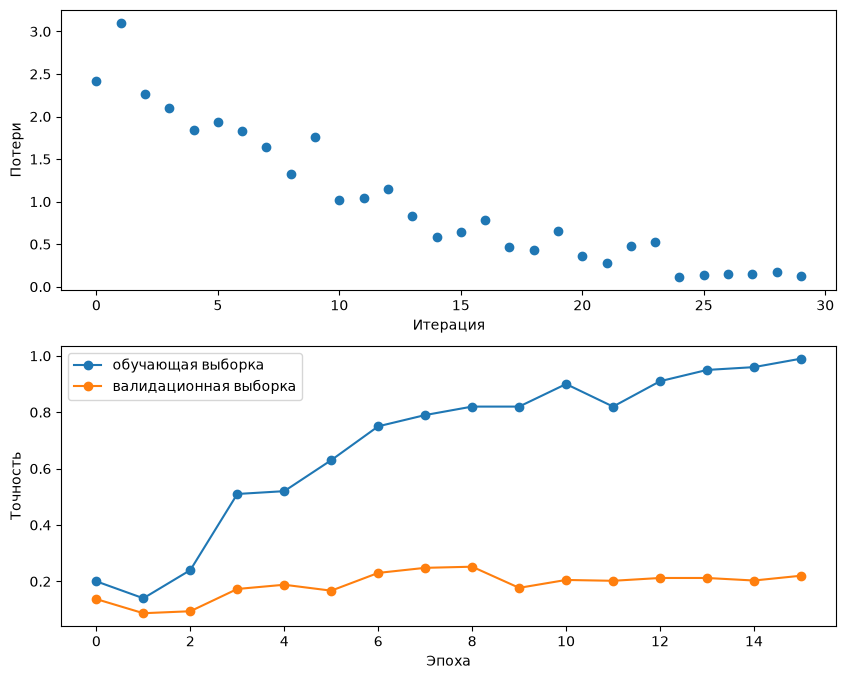

In [18]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.xlabel('Итерация')
plt.ylabel('Потери')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['обучающая выборка', 'валидационная выборка'], loc='upper left')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.show()

## Обучение сети
Если обучить трёхслойную свёрточную сеть в течение одной эпохи, точность на обучающей выборке должна превысить 40%:

In [19]:
np.random.seed(231)
model = ThreeLayerConvNet(weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(
    model,
    data,
    num_epochs=1,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3,},
    verbose=True,
    print_every=20
)
solver.train()

(Итерация 1 / 980) потери: 2.304677


(Эпоха 0 / 1) точность на обучении: 0.107000; на валидации: 0.112000


(Итерация 21 / 980) потери: 2.000045


(Итерация 41 / 980) потери: 2.103242


(Итерация 61 / 980) потери: 1.693575


(Итерация 81 / 980) потери: 1.828214


... (41 outputs left out)

(Итерация 921 / 980) потери: 1.629226


(Итерация 941 / 980) потери: 1.467005


(Итерация 961 / 980) потери: 1.790033


(Эпоха 1 / 1) точность на обучении: 0.475000; на валидации: 0.477000


In [20]:
# Выводим итоговую точность на обучающей выборке.
print(
    "Полный набор данных — точность на обучающей выборке:",
    solver.check_accuracy(data['X_train'], data['y_train'])
)

Полный набор данных — точность на обучающей выборке: 0.4749795918367347


In [21]:
# Выводим итоговую точность на валидационной выборке.
print(
    "Полный набор данных — точность на валидационной выборке:",
    solver.check_accuracy(data['X_val'], data['y_val'])
)

Полный набор данных — точность на валидационной выборке: 0.477


## Визуализация фильтров
Свёрточные фильтры первого слоя обученной сети можно визуализировать, запустив следующую ячейку:

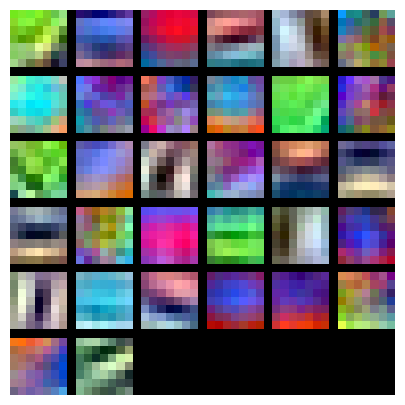

In [22]:
from dlcv.vis_utils import visualize_grid

grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))
plt.imshow(grid.astype('uint8'))
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()

# Пространственная батч-нормализация
Мы уже убедились, что батч-нормализация (batch normalization) — очень полезный приём для обучения глубоких полносвязных сетей. Как предложено ещё в оригинальной статье [1] (она уже упоминалась в ноутбуке `BatchNormalization.ipynb`), батч-нормализацию можно применять и в свёрточных сетях, но её нужно немного изменить. Такую модификацию называют пространственной батч-нормализацией (spatial batch normalization).

Обычная батч-нормализация принимает входы формы `(N, D)` и возвращает выходы формы `(N, D)`; нормализация при этом выполняется по измерению мини-батча `N`. Для данных, полученных от свёрточных слоёв, батч-нормализация должна принимать входы формы `(N, C, H, W)` и возвращать выходы формы `(N, C, H, W)`, где `N` — размер мини-батча, а `(H, W)` — пространственные размеры карты признаков.

Если карта признаков получена с помощью свёрток, то статистики каждого канала признаков (например, среднее и дисперсия) должны быть примерно одинаковыми как для разных изображений, так и для разных позиций внутри одного изображения: ведь каждый канал признаков порождается одним и тем же свёрточным фильтром! Поэтому пространственная батч-нормализация вычисляет среднее и дисперсию для каждого из `C` каналов признаков, собирая статистики не только по измерению мини-батча `N`, но и по пространственным измерениям `H` и `W`.


[1] [Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift", ICML 2015.](https://arxiv.org/abs/1502.03167)

# Пространственная батч-нормализация: прямой проход

В файле `dlcv/layers.py` реализуйте прямой проход пространственной батч-нормализации в функции `spatial_batchnorm_forward`. Проверьте реализацию, запустив следующие ячейки:

In [23]:
np.random.seed(231)

# Проверяем прямой проход в режиме обучения: смотрим на средние и дисперсии
# признаков до и после пространственной батч-нормализации.
N, C, H, W = 2, 3, 4, 5
x = 4 * np.random.randn(N, C, H, W) + 10

print('До пространственной батч-нормализации:')
print('  форма: ', x.shape)
print('  средние: ', x.mean(axis=(0, 2, 3)))
print('  стандартные отклонения: ', x.std(axis=(0, 2, 3)))

# Средние должны быть близки к нулю, а стандартные отклонения — к единице
gamma, beta = np.ones(C), np.zeros(C)
bn_param = {'mode': 'train'}
out, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)
print('После пространственной батч-нормализации:')
print('  форма: ', out.shape)
print('  средние: ', out.mean(axis=(0, 2, 3)))
print('  стандартные отклонения: ', out.std(axis=(0, 2, 3)))

# Средние должны быть близки к beta, а стандартные отклонения — к gamma
gamma, beta = np.asarray([3, 4, 5]), np.asarray([6, 7, 8])
out, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)
print('После пространственной батч-нормализации (нетривиальные gamma, beta):')
print('  форма: ', out.shape)
print('  средние: ', out.mean(axis=(0, 2, 3)))
print('  стандартные отклонения: ', out.std(axis=(0, 2, 3)))

До пространственной батч-нормализации:
  форма:  (2, 3, 4, 5)
  средние:  [9.33463814 8.90909116 9.11056338]
  стандартные отклонения:  [3.61447857 3.19347686 3.5168142 ]
После пространственной батч-нормализации:
  форма:  (2, 3, 4, 5)
  средние:  [ 5.85642645e-16  5.93969318e-16 -8.88178420e-17]
  стандартные отклонения:  [0.99999962 0.99999951 0.9999996 ]
После пространственной батч-нормализации (нетривиальные gamma, beta):
  форма:  (2, 3, 4, 5)
  средние:  [6. 7. 8.]
  стандартные отклонения:  [2.99999885 3.99999804 4.99999798]


In [24]:
np.random.seed(231)

# Проверяем прямой проход в режиме тестирования: сначала много раз
# выполняем прямой проход в режиме обучения, чтобы «прогреть» скользящие
# средние, а затем смотрим на средние и дисперсии активаций после прямого
# прохода в режиме тестирования.
N, C, H, W = 10, 4, 11, 12

bn_param = {'mode': 'train'}
gamma = np.ones(C)
beta = np.zeros(C)
for t in range(50):
  x = 2.3 * np.random.randn(N, C, H, W) + 13
  spatial_batchnorm_forward(x, gamma, beta, bn_param)
bn_param['mode'] = 'test'
x = 2.3 * np.random.randn(N, C, H, W) + 13
a_norm, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)

# Средние должны быть близки к нулю, а стандартные отклонения — к единице,
# но разброс будет больше, чем при прямом проходе в режиме обучения.
print('После пространственной батч-нормализации (режим тестирования):')
print('  средние: ', a_norm.mean(axis=(0, 2, 3)))
print('  стандартные отклонения: ', a_norm.std(axis=(0, 2, 3)))

После пространственной батч-нормализации (режим тестирования):
  средние:  [-0.08034406  0.07562881  0.05716371  0.04378383]
  стандартные отклонения:  [0.96718744 1.0299714  1.02887624 1.00585577]


# Пространственная батч-нормализация: обратный проход
В файле `dlcv/layers.py` реализуйте обратный проход пространственной батч-нормализации в функции `spatial_batchnorm_backward`. Запустите следующую ячейку, чтобы проверить реализацию с помощью численной проверки градиента:

In [25]:
np.random.seed(231)
N, C, H, W = 2, 3, 4, 5
x = 5 * np.random.randn(N, C, H, W) + 12
gamma = np.random.randn(C)
beta = np.random.randn(C)
dout = np.random.randn(N, C, H, W)

bn_param = {'mode': 'train'}
fx = lambda x: spatial_batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: spatial_batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: spatial_batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

# Ошибки должны быть в диапазоне от 1e-12 до 1e-06
_, cache = spatial_batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = spatial_batchnorm_backward(dout, cache)
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dgamma: ', rel_error(da_num, dgamma))
print('ошибка dbeta: ', rel_error(db_num, dbeta))

ошибка dx:  3.0838468285639314e-07
ошибка dgamma:  7.09738489671469e-12
ошибка dbeta:  3.275608725278405e-12


# Пространственная групповая нормализация
В ноутбуке `BatchNormalization.ipynb` говорилось, что нормализация по слою (layer normalization) — альтернативный метод нормализации, который снимает ограничения батч-нормализации, связанные с размером батча. Однако, как заметили авторы [2], в свёрточных слоях нормализация по слою работает хуже батч-нормализации:

> В полносвязных слоях все нейроны слоя, как правило, вносят схожий вклад в итоговое предсказание, поэтому центрирование и масштабирование суммарных входов слоя хорошо работают. Однако в свёрточных нейронных сетях предположение о схожем вкладе уже не выполняется. Многие нейроны, рецептивные поля которых расположены у границы изображения, активируются редко, и поэтому их статистики сильно отличаются от статистик остальных нейронов того же слоя.

Авторы [3] предлагают промежуточный подход. В отличие от нормализации по слою, где для каждого примера нормализуется весь вектор признаков целиком, они предлагают единообразно разбивать признаки каждого примера на G групп и нормализовать каждую группу каждого примера по отдельности.

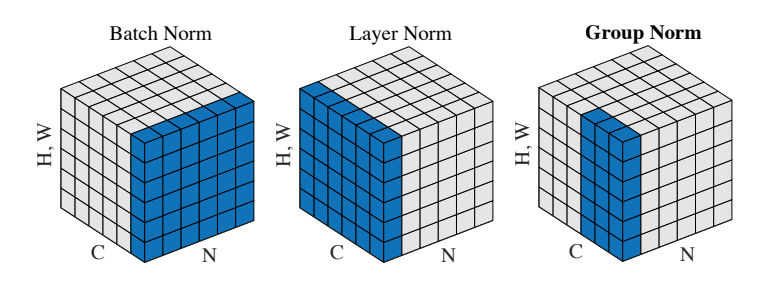

<center>Наглядное сравнение рассмотренных методов нормализации (изображение из [3] с изменениями)</center>

Внутри каждой группы по-прежнему предполагается, что все признаки вносят одинаковый вклад, но авторы считают, что это не так уж страшно, поскольку в задачах распознавания изображений признаки естественным образом объединяются в группы. В качестве примера они указывают, что во многих эффективных признаках, сконструированных вручную в классическом компьютерном зрении, компоненты явно сгруппированы. Возьмём, например, гистограмму направленных градиентов (HOG) [4]: гистограммы вычисляются по отдельным локальным блокам изображения, и каждая такая гистограмма нормализуется по отдельности, прежде чем все они объединяются в итоговый вектор признаков.

Теперь вы реализуете групповую нормализацию (group normalization).

[2] [Ba, Jimmy Lei, Jamie Ryan Kiros, and Geoffrey E. Hinton. "Layer Normalization." stat 1050 (2016): 21.](https://arxiv.org/pdf/1607.06450.pdf)


[3] [Wu, Yuxin, and Kaiming He. "Group Normalization." arXiv preprint arXiv:1803.08494 (2018).](https://arxiv.org/abs/1803.08494)


[4] [N. Dalal and B. Triggs. Histograms of oriented gradients for
human detection. In Computer Vision and Pattern Recognition
(CVPR), 2005.](https://ieeexplore.ieee.org/abstract/document/1467360/)

# Пространственная групповая нормализация: прямой проход

В файле `dlcv/layers.py` реализуйте прямой проход групповой нормализации в функции `spatial_groupnorm_forward`. Проверьте реализацию, запустив следующую ячейку:

In [26]:
np.random.seed(231)

# Проверяем прямой проход в режиме обучения: смотрим на средние и дисперсии
# признаков до и после пространственной групповой нормализации.
N, C, H, W = 2, 6, 4, 5
G = 2
x = 4 * np.random.randn(N, C, H, W) + 10
x_g = x.reshape((N*G,-1))
print('До пространственной групповой нормализации:')
print('  форма: ', x.shape)
print('  средние: ', x_g.mean(axis=1))
print('  стандартные отклонения: ', x_g.std(axis=1))

# Средние должны быть близки к нулю, а стандартные отклонения — к единице
gamma, beta = np.ones((1,C,1,1)), np.zeros((1,C,1,1))
bn_param = {'mode': 'train'}

out, _ = spatial_groupnorm_forward(x, gamma, beta, G, bn_param)
out_g = out.reshape((N*G,-1))
print('После пространственной групповой нормализации:')
print('  форма: ', out.shape)
print('  средние: ', out_g.mean(axis=1))
print('  стандартные отклонения: ', out_g.std(axis=1))

До пространственной групповой нормализации:
  форма:  (2, 6, 4, 5)
  средние:  [9.72505327 8.51114185 8.9147544  9.43448077]
  стандартные отклонения:  [3.67070958 3.09892597 4.27043622 3.97521327]
После пространственной групповой нормализации:
  форма:  (2, 6, 4, 5)
  средние:  [-2.14643118e-16  5.25505565e-16  2.58126853e-16 -3.62672855e-16]
  стандартные отклонения:  [0.99999963 0.99999948 0.99999973 0.99999968]


# Пространственная групповая нормализация: обратный проход
В файле `dlcv/layers.py` реализуйте обратный проход пространственной групповой нормализации в функции `spatial_groupnorm_backward`. Запустите следующую ячейку, чтобы проверить реализацию с помощью численной проверки градиента:

In [27]:
np.random.seed(231)
N, C, H, W = 2, 6, 4, 5
G = 2
x = 5 * np.random.randn(N, C, H, W) + 12
gamma = np.random.randn(1,C,1,1)
beta = np.random.randn(1,C,1,1)
dout = np.random.randn(N, C, H, W)

gn_param = {}
fx = lambda x: spatial_groupnorm_forward(x, gamma, beta, G, gn_param)[0]
fg = lambda a: spatial_groupnorm_forward(x, a, beta, G, gn_param)[0]
fb = lambda b: spatial_groupnorm_forward(x, gamma, b, G, gn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = spatial_groupnorm_forward(x, gamma, beta, G, gn_param)
dx, dgamma, dbeta = spatial_groupnorm_backward(dout, cache)

# Ошибки должны быть в диапазоне от 1e-12 до 1e-07.
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dgamma: ', rel_error(da_num, dgamma))
print('ошибка dbeta: ', rel_error(db_num, dbeta))

ошибка dx:  6.34590429868661e-08
ошибка dgamma:  1.0546047434202244e-11
ошибка dbeta:  3.810857316122484e-12
